# Organic vs. Recyclable Waste — DCNN (Table 2), run 3: shorter training + early stopping + stronger regularization

Kaggle notebook for the from-scratch Table 2 model from `EXPERIMENT-PLAN.md`. It uses the audited `splits.csv` and the official Kaggle `TEST` folder.

## Kaggle setup
1. Enable a GPU accelerator (one GPU is used; no DataParallel).
2. Add the Kaggle dataset `techsash/waste-classification-data` as an input.
3. Add the small Kaggle input dataset containing this project's `splits.csv`.
4. **Save Version → Save & Run All (Commit)**.

The split is still **provisional** (see `dataset/README.md`): 552/2,513 test images are flagged by MD5/dHash matching. Both full-test and unflagged-test metrics are reported; a flag is not proof of semantic leakage.

## Why this run exists

Run 2 (100 epochs, LR 1e-4, AdamW wd 1e-4, cosine, flip + crop) overfit strongly:
train accuracy reached 99.8%, **validation loss was lowest at epoch 23 (0.30) and doubled to 0.61 by epoch 100**, and validation accuracy was flat (~90.5%) from about epoch 72. The extra 77 epochs cost about 4 GPU-hours and mainly made the model over-confident.

## Changes in this run (all `[OURS]`, relative to run 2)

| Setting | Run 2 | Run 3 (this notebook) | Reason |
|---|---|---|---|
| Max epochs | 100 | **40** | Val loss bottomed at epoch 23 in run 2 |
| Early stopping | none | **val NLL, patience 8, min_delta 1e-3, no stop before epoch 12** | Stop once the model only memorises |
| Checkpoint rule | best val accuracy | **best val macro-F1** (tie: lower val NLL) | Balanced across both classes |
| Cosine schedule | over 100 epochs | over 40 epochs | LR actually decays inside the shorter budget |
| Weight decay (AdamW) | 1e-4 | **0.05** | With LR 1e-4, wd 1e-4 shrinks weights by ~0.3% over the whole run, which is effectively no regularization |
| Dropout before output | 0.25 (paper) | **0.5** | The 802,816→128 Dense layer holds 98.9% of the parameters |
| Label smoothing | 0 | **0.1** (training loss only) | Counters the over-confidence seen as rising val loss |
| Augmentation (train only) | flip + 8 px reflect crop | **RandomResizedCrop(scale 0.6–1) + flip + ColorJitter(0.2)** | More variation per image |
| Validation loss | plain CE | plain CE (unsmoothed NLL) | Comparable with run 2 and not distorted by smoothing |

Unchanged: Table 2 architecture (103,935,010 trainable parameters), LR 1e-4, batch 64, AMP with the FC classifier in FP32, seed 42, the split, and test-set isolation.

**Caveat for the report:** this run changes several factors at once relative to run 2. It answers "does a regularized, shorter protocol reduce overfitting?" but not which factor is responsible. Use `REG_PRESET` below to run single-factor ablations later.

Optional architecture change (off by default): `HEAD = 'gap'` replaces Flatten→Dense(802,816→128) with global average pooling→Dense(256→128) (about 1.2 M parameters in total). This is no longer the paper's architecture and must be reported as an improvement experiment, not a reproduction.

Expected time on a T4: about 6.5 min for caching, then about 3 min per epoch, so at most about 2 hours (less if early stopping triggers).

In [1]:
import os
os.environ['PYTHONHASHSEED'] = '42'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

from concurrent.futures import ThreadPoolExecutor
import hashlib
import json
import random
import time
import tempfile
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 64
QUICK_TEST = False  # False = full run (100 epochs, test evaluated once); True = smoke test only
EPOCHS = 3 if QUICK_TEST else 40   # [OURS] max epochs; run 2 val loss bottomed at epoch 23
QUICK_TRAIN, QUICK_VAL = 2000, 1000
LR = 1e-4  # [OURS] stability adjustment; paper reports 1e-3
COSINE = True         # [OURS] cosine LR decay over EPOCHS; paper uses constant LR

# Early stopping [OURS]: monitor unsmoothed validation NLL; checkpoint by validation macro-F1.
EARLY_STOP_PATIENCE = 8     # epochs without val-NLL improvement before stopping
EARLY_STOP_MIN_DELTA = 1e-3 # smaller improvements do not reset patience
MIN_EPOCHS = 12             # never stop before this epoch (LR still high, curves noisy)

# Regularization presets [OURS]. 'run3' = all changes at once; the others change one factor vs run 2.
REG_PRESET = 'run3'
PRESETS = {
    'run2':        dict(weight_decay=1e-4, dropout=0.25, label_smoothing=0.0, augment='flip_crop'),
    'run3':        dict(weight_decay=0.05, dropout=0.5,  label_smoothing=0.1, augment='strong'),
    'only_wd':     dict(weight_decay=0.05, dropout=0.25, label_smoothing=0.0, augment='flip_crop'),
    'only_dropout':dict(weight_decay=1e-4, dropout=0.5,  label_smoothing=0.0, augment='flip_crop'),
    'only_ls':     dict(weight_decay=1e-4, dropout=0.25, label_smoothing=0.1, augment='flip_crop'),
    'only_aug':    dict(weight_decay=1e-4, dropout=0.25, label_smoothing=0.0, augment='strong'),
}
REG = PRESETS[REG_PRESET]
WEIGHT_DECAY = REG['weight_decay']        # AdamW decoupled weight decay; paper uses 0
DROPOUT = REG['dropout']                  # paper: 0.25
LABEL_SMOOTHING = REG['label_smoothing']  # training loss only
AUGMENT = REG['augment']                  # 'none' | 'flip_crop' (run 2) | 'strong'
HEAD = 'paper'  # 'paper' = Table 2 Flatten->Dense(802816->128); 'gap' = [OURS, architecture change]
AUGMENTATION_NAME = {'none': 'none', 'flip_crop': 'flip + reflect-pad 8 px crop',
                     'strong': 'RandomResizedCrop(0.6-1) + flip + ColorJitter(0.2)'}[AUGMENT]
IMAGE_SIZE = 224
OUT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd() / 'results'
OUT.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE)
print('PyTorch:', torch.__version__)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    print('Visible GPUs:', torch.cuda.device_count(), '(this notebook uses cuda:0 only)')
    print('GPU memory (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
else:
    print('No GPU detected; this full 100-epoch model is intended for Kaggle GPU.')
CONFIG = {'run': 'run3', 'reg_preset': REG_PRESET, 'seed': SEED, 'image_size': IMAGE_SIZE,
          'batch_size': BATCH_SIZE, 'max_epochs': EPOCHS,
          'optimizer': 'AdamW', 'betas': [0.9, 0.999], 'eps': 1e-7,
          'learning_rate': LR, 'lr_note': 'stability adjustment; paper reports 1e-3',
          'scheduler': f'cosine over {EPOCHS} epochs' if COSINE else 'constant',
          'model': 'Table2' if HEAD == 'paper' else 'Table2_conv + GAP head', 'head': HEAD,
          'dropout': DROPOUT, 'leaky_relu_slope': 0.25, 'weight_decay': WEIGHT_DECAY,
          'label_smoothing_train': LABEL_SMOOTHING, 'augmentation': AUGMENTATION_NAME,
          'early_stopping': {'monitor': 'val_nll', 'patience': EARLY_STOP_PATIENCE,
                             'min_delta': EARLY_STOP_MIN_DELTA, 'min_epochs': MIN_EPOCHS},
          'checkpoint_rule': 'max val macro-F1, tie -> lower val NLL',
          'amp': DEVICE.type == 'cuda', 'fc_in_fp32': True,
          'splits_md5': 'filled after split validation'}
environment = {'python': __import__('sys').version, 'pytorch': torch.__version__,
               'device': str(DEVICE), 'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None}
(OUT / 'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
(OUT / 'env.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')


Device: cuda:0
PyTorch: 2.11.0+cu130
GPU: Tesla T4
Visible GPUs: 2 (this notebook uses cuda:0 only)
GPU memory (GiB): 14.6


140

## 1. Load the audited split and locate Kaggle images

The audit CSV contains absolute paths from the Kaggle run that created it. This cell maps the suffix beginning at `DATASET/` onto the currently attached dataset root, so the CSV remains usable when Kaggle mounts it under a different input directory.

In [2]:
EXPECTED_SPLITS_MD5 = '66c0bcf5ba56ddfe7bc0ba4d5246e7a8'
input_root = Path('/kaggle/input')
csv_candidates = sorted(input_root.rglob('splits.csv')) if input_root.exists() else []
if not csv_candidates:
    raise FileNotFoundError('Attach a Kaggle input dataset containing dataset/splits.csv.')
splits_path = csv_candidates[0]
splits_md5 = hashlib.md5(splits_path.read_bytes()).hexdigest()
assert splits_md5 == EXPECTED_SPLITS_MD5, (
    f'Unexpected splits.csv MD5 {splits_md5}; update the expected hash only after reviewing the new audit.'
)
df = pd.read_csv(splits_path)
required = {'path', 'label', 'split', 'group_id', 'test_leak'}
assert required.issubset(df.columns), f'Missing columns: {required - set(df.columns)}'
assert len(df) == 25077 and set(df['split']) == {'train', 'val', 'test'}
CONFIG['splits_md5'] = splits_md5
(OUT / 'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
train_groups = set(df.loc[df.split == 'train', 'group_id'])
val_groups = set(df.loc[df.split == 'val', 'group_id'])
assert train_groups.isdisjoint(val_groups), 'A duplicate group crosses train/validation.'
test_groups = set(df.loc[df.split == 'test', 'group_id'])
print('Test groups shared with train:', len(test_groups & train_groups),
      '| shared with val:', len(test_groups & val_groups))

# Kaggle archives may contain two identical DATASET trees; use the first matching tree.
roots = sorted(p.parent for p in input_root.rglob('TRAIN')
               if p.is_dir() and (p.parent / 'TEST').is_dir()
               and (p / 'O').is_dir() and (p / 'R').is_dir())
assert roots, 'Could not find a folder containing TRAIN/O, TRAIN/R, and TEST.'
def resolve_image_path(raw_path):
    parts = PurePosixPath(str(raw_path).replace('\\', '/')).parts
    upper = [part.upper() for part in parts]
    if 'DATASET' in upper:
        tail = parts[upper.index('DATASET') + 1:]
    else:
        tail = parts[-3:]
    for root in roots:
        candidate = root.joinpath(*tail)
        if candidate.is_file():
            return str(candidate)
    raise FileNotFoundError(f'Cannot map audited path to attached dataset: {raw_path}')

df['resolved_path'] = df['path'].map(resolve_image_path)
assert df['resolved_path'].map(lambda p: Path(p).is_file()).all()
print('Split file:', splits_path)
print('splits.csv MD5:', splits_md5)
print('Image root used:', roots[0])
print(pd.crosstab(df['split'], df['label'], margins=True))
print('Test leak flags:', int(((df.split == 'test') & (df.test_leak == 1)).sum()), '/', int((df.split == 'test').sum()))

Test groups shared with train: 329 | shared with val: 0
Split file: /kaggle/input/datasets/hahuy1708/waste-cnn-classify-split/splits.csv
splits.csv MD5: 66c0bcf5ba56ddfe7bc0ba4d5246e7a8
Image root used: /kaggle/input/datasets/techsash/waste-classification-data/DATASET
label      0      1    All
split                     
test    1401   1112   2513
train  10829   8712  19541
val     1736   1287   3023
All    13966  11111  25077
Test leak flags: 552 / 2513


## 2. Build a one-time resized image cache

Decode and resize each image once to RGB 224×224, then reuse the memory-mapped `uint8` cache across epochs. The cache lives in temporary Kaggle storage rather than the downloadable results. Normalization statistics are computed from the training split only.

In [3]:
train_ids = df.index[df.split == 'train'].to_numpy()
val_ids = df.index[df.split == 'val'].to_numpy()
test_ids = df.index[df.split == 'test'].to_numpy()
if QUICK_TEST:
    rng_quick = np.random.default_rng(SEED)
    train_ids = rng_quick.choice(train_ids, min(QUICK_TRAIN, len(train_ids)), replace=False)
    val_ids = rng_quick.choice(val_ids, min(QUICK_VAL, len(val_ids)), replace=False)
    test_ids = test_ids[:0]   # test set not used in quick mode
cache_ids = np.sort(np.concatenate((train_ids, val_ids)))
QUICK_SUFFIX = '_quick' if QUICK_TEST else ''
cache_path = Path(tempfile.gettempdir()) / f'waste_trainval_224_{splits_md5[:12]}{QUICK_SUFFIX}.npy'
ready_path = cache_path.with_suffix('.ready')
cache_shape = (len(df), IMAGE_SIZE, IMAGE_SIZE, 3)

def resize_row(row):
    with Image.open(df.at[row, 'resolved_path']) as image:
        pixels = np.asarray(image.convert('RGB').resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR))
    return row, pixels

if cache_path.exists() and ready_path.exists():
    cache = np.load(cache_path, mmap_mode='r+')
    assert cache.shape == cache_shape, f'Bad cache shape: {cache.shape}'
    print('Reusing train/validation cache:', cache_path)
else:
    cache_path.unlink(missing_ok=True)
    ready_path.unlink(missing_ok=True)
    cache = np.lib.format.open_memmap(cache_path, mode='w+', dtype=np.uint8, shape=cache_shape)
    started = time.time()
    workers = min(8, os.cpu_count() or 4)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for n, (row, pixels) in enumerate(pool.map(resize_row, cache_ids), 1):
            cache[row] = pixels
            if n % 2000 == 0 or n == len(cache_ids):
                print(f'Cached train/validation {n:,}/{len(cache_ids):,}')
    cache.flush()
    ready_path.write_text(splits_md5, encoding='ascii')
    print(f'Train/validation cache built in {(time.time() - started) / 60:.1f} min:', cache_path)

channel_sum = np.zeros(3, dtype=np.float64)
channel_sq_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0
for start in range(0, len(train_ids), 128):
    batch = np.asarray(cache[train_ids[start:start + 128]], dtype=np.float32) / 255.0
    channel_sum += batch.sum(axis=(0, 1, 2))
    channel_sq_sum += np.square(batch).sum(axis=(0, 1, 2))
    pixel_count += batch.shape[0] * IMAGE_SIZE * IMAGE_SIZE
mean = (channel_sum / pixel_count).astype(np.float32)
std = np.sqrt(channel_sq_sum / pixel_count - mean ** 2).astype(np.float32)
print('Train-only channel mean:', mean.round(4))
print('Train-only channel std:', std.round(4))
print('Image dtype after normalization will be float32:', (np.ones(1, dtype=np.float32) - mean[0]).dtype)

Cached train/validation 2,000/22,564
Cached train/validation 4,000/22,564
Cached train/validation 6,000/22,564
Cached train/validation 8,000/22,564
Cached train/validation 10,000/22,564
Cached train/validation 12,000/22,564
Cached train/validation 14,000/22,564
Cached train/validation 16,000/22,564
Cached train/validation 18,000/22,564
Cached train/validation 20,000/22,564
Cached train/validation 22,000/22,564
Cached train/validation 22,564/22,564
Train/validation cache built in 5.8 min: /tmp/waste_trainval_224_66c0bcf5ba56.npy
Train-only channel mean: [0.694  0.6452 0.5703]
Train-only channel std: [0.2883 0.3    0.3449]
Image dtype after normalization will be float32: float32


## 3. Define the PyTorch dataset and B0 model

The layer order follows Table 2: Conv → LeakyReLU → BatchNorm; pools follow convolution 4 and 6. Initialization and BatchNorm settings mirror the Keras defaults inferred in the plan.

In [4]:
from torchvision.transforms import v2 as T

# Train-only augmentation. All randomness comes from torch, so DataLoader workers are seeded by torch.
STRONG_AUG = T.Compose([
    T.RandomResizedCrop(IMAGE_SIZE, scale=(0.6, 1.0), ratio=(3 / 4, 4 / 3), antialias=True),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])
MEAN_T = torch.tensor(mean).view(3, 1, 1)
STD_T = torch.tensor(std).view(3, 1, 1)
NUM_WORKERS = min(4, os.cpu_count() or 2)

class WasteImages(Dataset):
    def __init__(self, row_ids, augment='none'):
        self.row_ids = np.asarray(row_ids)
        self.augment = augment
        self.labels = df['label'].to_numpy(dtype=np.int64)
    def __len__(self):
        return len(self.row_ids)
    def __getitem__(self, item):
        row = int(self.row_ids[item])
        image = np.array(cache[row], dtype=np.uint8, copy=True)
        if self.augment == 'flip_crop':  # run 2 augmentation, kept for ablations
            if torch.rand(1).item() < 0.5:
                image = np.ascontiguousarray(image[:, ::-1, :])
            pad = 8
            padded = np.pad(image, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
            top, left = torch.randint(0, 2 * pad + 1, (2,)).tolist()
            image = padded[top:top + IMAGE_SIZE, left:left + IMAGE_SIZE]
        tensor = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1)))  # uint8 CHW
        if self.augment == 'strong':
            tensor = STRONG_AUG(tensor)
        tensor = (tensor.float() / 255.0 - MEAN_T) / STD_T
        label = torch.tensor(self.labels[row], dtype=torch.long)
        return tensor, label

def make_loader(row_ids, augment='none', shuffle=False):
    return DataLoader(WasteImages(row_ids, augment=augment), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
                      persistent_workers=True)

train_loader = make_loader(train_ids, augment=AUGMENT, shuffle=True)
val_loader = make_loader(val_ids)
print('Training batches per epoch:', len(train_loader), '| validation batches:', len(val_loader))

class DCNN(nn.Module):
    def __init__(self, head='paper', dropout=0.25):
        super().__init__()
        layers = []
        channels = [3, 32, 32, 64, 64, 128, 128, 256, 256]
        for i in range(8):
            layers.extend([nn.Conv2d(channels[i], channels[i + 1], 3, padding=1, bias=True),
                           nn.LeakyReLU(negative_slope=0.25, inplace=True),
                           nn.BatchNorm2d(channels[i + 1], eps=1e-3, momentum=0.01)])
            if i in (3, 5):
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
        self.features = nn.Sequential(*layers)
        self.head = head
        in_features = 256 * 56 * 56 if head == 'paper' else 256  # 'gap': global average pooling
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(in_features, 128),
            nn.LeakyReLU(negative_slope=0.25, inplace=True),
            nn.Dropout(p=dropout), nn.Linear(128, 2))
        self.apply(self._init_weights)
    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    def forward(self, x):
        features = self.features(x)
        if self.head == 'gap':
            features = features.mean(dim=(2, 3))  # deterministic, unlike AdaptiveAvgPool2d backward
        # The Flatten-to-Dense layer dominates the model; keep its logits out of FP16.
        with torch.autocast(device_type=features.device.type, enabled=False):
            return self.classifier(features.float())

MODEL_KW = dict(head=HEAD, dropout=DROPOUT)
model = DCNN(**MODEL_KW).to(DEVICE)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
bn_buffers = sum(b.numel() for name, b in model.named_buffers() if 'running_' in name)
print(f'Trainable parameters: {trainable_params:,}; BN running stats: {bn_buffers:,}')
if HEAD == 'paper':
    assert trainable_params == 103_935_010 and bn_buffers == 1_920

Training batches per epoch: 306 | validation batches: 48
Trainable parameters: 103,935,010; BN running stats: 1,920


## 4. Train with early stopping (max 40 epochs)

One GPU (`cuda:0`), AMP FP16 for the convolutions and FP32 for the classifier.

- **Training loss:** cross-entropy with label smoothing `LABEL_SMOOTHING`.
- **Validation loss (NLL):** plain cross-entropy, so it is comparable with run 2 and is not inflated by smoothing.
- **Early stopping:** stop when validation NLL has not improved by at least `EARLY_STOP_MIN_DELTA` for `EARLY_STOP_PATIENCE` epochs, but never before `MIN_EPOCHS`.
- **Checkpoint:** the epoch with the highest validation macro-F1 (tie: lower validation NLL). The stopping signal (NLL) and the selection metric (macro-F1) are deliberately different: NLL detects the start of memorisation, macro-F1 picks the best classifier seen up to that point.
- `last.pt` is written every epoch (model + optimizer + scheduler + scaler + history) so a stopped session can be inspected or resumed.

In [5]:
criterion_train = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
criterion_eval = nn.CrossEntropyLoss()  # unsmoothed NLL for monitoring and early stopping
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.999), eps=1e-7,
                              weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS) if COSINE else None
scaler = torch.amp.GradScaler('cuda', enabled=DEVICE.type == 'cuda')
history = []
best_val_f1 = -1.0
best_val_loss = float('inf')   # val NLL of the selected checkpoint (tie-breaker)
best_epoch = None
best_state = None
lowest_val_nll = float('inf')  # early-stopping monitor
lowest_val_nll_epoch = None
epochs_without_improvement = 0
stopped_epoch = None

def epoch_metrics(labels, predictions, probabilities, loss_sum, count):
    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        'loss': loss_sum / count,
        'accuracy': accuracy_score(labels, predictions),
        'precision': precision_score(labels, predictions, pos_label=1, zero_division=0),
        'recall': recall_score(labels, predictions, pos_label=1, zero_division=0),
        'f1': f1_score(labels, predictions, pos_label=1, zero_division=0),
        'macro_f1': f1_score(labels, predictions, average='macro', zero_division=0),
        'auc': roc_auc_score(labels, probabilities),
        'mdr': fn / max(fn + tp, 1),
        'fdr': fp / max(fp + tp, 1),
        'fpr': fp / max(fp + tn, 1),
    }

def run_epoch(loader, training):
    model.train(training)
    all_y, all_pred, all_prob = [], [], []
    loss_sum = 0.0
    count = 0
    peak_logit = 0.0
    context = torch.enable_grad if training else torch.no_grad
    with context():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == 'cuda'):
                logits = model(images)
                if not torch.isfinite(logits).all():
                    phase = 'train' if training else 'validation'
                    raise FloatingPointError(f'Non-finite logits during {phase}; inspect LR/BN/AMP.')
                loss = (criterion_train if training else criterion_eval)(logits, labels)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            probs = torch.softmax(logits.detach().float(), dim=1)[:, 1]
            if not torch.isfinite(probs).all():
                raise FloatingPointError('Non-finite class probabilities; check logits/AMP stability.')
            peak_logit = max(peak_logit, logits.detach().abs().max().item())
            preds = logits.detach().argmax(dim=1)
            n = labels.size(0)
            loss_sum += loss.item() * n
            count += n
            all_y.extend(labels.cpu().numpy())
            all_pred.extend(preds.cpu().numpy())
            all_prob.extend(probs.float().cpu().numpy())
    result = epoch_metrics(np.asarray(all_y), np.asarray(all_pred), np.asarray(all_prob), loss_sum, count)
    result['peak_logit'] = peak_logit
    return result

for epoch in range(1, EPOCHS + 1):
    started = time.time()
    train_m = run_epoch(train_loader, training=True)
    val_m = run_epoch(val_loader, training=False)
    row = {'epoch': epoch, 'lr': optimizer.param_groups[0]['lr'],
           **{f'train_{k}': v for k, v in train_m.items()},
           **{f'val_{k}': v for k, v in val_m.items()},
           'epoch_time_s': time.time() - started}
    if scheduler is not None:
        scheduler.step()

    # Checkpoint selection: max val macro-F1, tie -> lower val NLL.
    is_best = (val_m['macro_f1'] > best_val_f1 or
               (val_m['macro_f1'] == best_val_f1 and val_m['loss'] < best_val_loss))
    if is_best:
        best_val_f1, best_val_loss = val_m['macro_f1'], val_m['loss']
        best_epoch = epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({'model_state': best_state, 'model_kw': MODEL_KW, 'epoch': epoch,
                    'val_metrics': val_m, 'config': CONFIG, 'splits_md5': splits_md5,
                    'mean': mean.tolist(), 'std': std.tolist()}, OUT / 'best.pt')

    # Early stopping monitor: unsmoothed val NLL.
    if val_m['loss'] < lowest_val_nll - EARLY_STOP_MIN_DELTA:
        lowest_val_nll, lowest_val_nll_epoch = val_m['loss'], epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    row.update({'is_best': is_best, 'epochs_without_val_nll_improvement': epochs_without_improvement,
                'train_val_acc_gap': train_m['accuracy'] - val_m['accuracy']})
    history.append(row)
    pd.DataFrame(history).to_csv(OUT / 'history.csv', index=False)
    torch.save({'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
                'scheduler_state': scheduler.state_dict() if scheduler is not None else None,
                'scaler_state': scaler.state_dict(), 'epoch': epoch, 'history': history,
                'best_epoch': best_epoch, 'best_val_f1': best_val_f1,
                'lowest_val_nll': lowest_val_nll, 'lowest_val_nll_epoch': lowest_val_nll_epoch,
                'epochs_without_improvement': epochs_without_improvement,
                'config': CONFIG, 'model_kw': MODEL_KW, 'splits_md5': splits_md5}, OUT / 'last.pt')

    print(f"Epoch {epoch:03d}/{EPOCHS} | "
          f"train loss {train_m['loss']:.4f} acc {train_m['accuracy']:.4f} "
          f"P/R {train_m['precision']:.4f}/{train_m['recall']:.4f} | "
          f"val loss {val_m['loss']:.4f} acc {val_m['accuracy']:.4f} "
          f"P/R {val_m['precision']:.4f}/{val_m['recall']:.4f} "
          f"macro-F1 {val_m['macro_f1']:.4f} | gap {row['train_val_acc_gap']:+.3f} | "
          f"no-improve {epochs_without_improvement}/{EARLY_STOP_PATIENCE}"
          f"{' *best*' if is_best else ''} | {row['epoch_time_s'] / 60:.1f} min")
    if epoch >= MIN_EPOCHS and epochs_without_improvement >= EARLY_STOP_PATIENCE:
        stopped_epoch = epoch
        print(f'Early stopping at epoch {epoch}: val NLL has not improved since epoch '
              f'{lowest_val_nll_epoch} ({lowest_val_nll:.4f}).')
        break

assert best_state is not None
del model
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
model = DCNN(**MODEL_KW).to(DEVICE)
model.load_state_dict(best_state)
epochs_run = len(history)
best_row = history[best_epoch - 1]
best_val_acc = best_row['val_accuracy']
print(f'Epochs run: {epochs_run}' + (f' (early stop at {stopped_epoch})' if stopped_epoch else ' (max reached)'))
print(f'Lowest val NLL: {lowest_val_nll:.4f} at epoch {lowest_val_nll_epoch}')
print(f"Selected checkpoint: epoch {best_epoch} | val macro-F1 {best_val_f1:.4f} | "
      f"val acc {best_val_acc:.4f} | val NLL {best_row['val_loss']:.4f} | "
      f"train-val acc gap {best_row['train_val_acc_gap']:+.4f}")
print(f"Training GPU time: {sum(r['epoch_time_s'] for r in history) / 3600:.2f} h")

Epoch 001/40 | train loss 4.7355 acc 0.7187 P/R 0.6845/0.6848 | val loss 2.5047 acc 0.7324 P/R 0.8830/0.4281 macro-F1 0.6905 | gap -0.014 | no-improve 0/8 *best* | 3.3 min
Epoch 002/40 | train loss 3.3789 acc 0.7394 P/R 0.7066/0.7106 | val loss 2.8640 acc 0.6953 P/R 0.6250/0.7110 macro-F1 0.6928 | gap +0.044 | no-improve 1/8 *best* | 3.5 min
Epoch 003/40 | train loss 2.8412 acc 0.7497 P/R 0.7185/0.7212 | val loss 2.9724 acc 0.7235 P/R 0.6245/0.8788 macro-F1 0.7233 | gap +0.026 | no-improve 2/8 *best* | 3.5 min
Epoch 004/40 | train loss 2.3129 acc 0.7547 P/R 0.7229/0.7293 | val loss 1.4806 acc 0.7966 P/R 0.7456/0.7925 macro-F1 0.7935 | gap -0.042 | no-improve 0/8 *best* | 3.5 min
Epoch 005/40 | train loss 1.8629 acc 0.7575 P/R 0.7246/0.7357 | val loss 1.1865 acc 0.7691 P/R 0.6926/0.8228 macro-F1 0.7680 | gap -0.012 | no-improve 0/8 | 3.5 min
Epoch 006/40 | train loss 1.4326 acc 0.7703 P/R 0.7397/0.7479 | val loss 0.9430 acc 0.8032 P/R 0.7486/0.8096 macro-F1 0.8006 | gap -0.033 | no-impr

## 5. Training curves

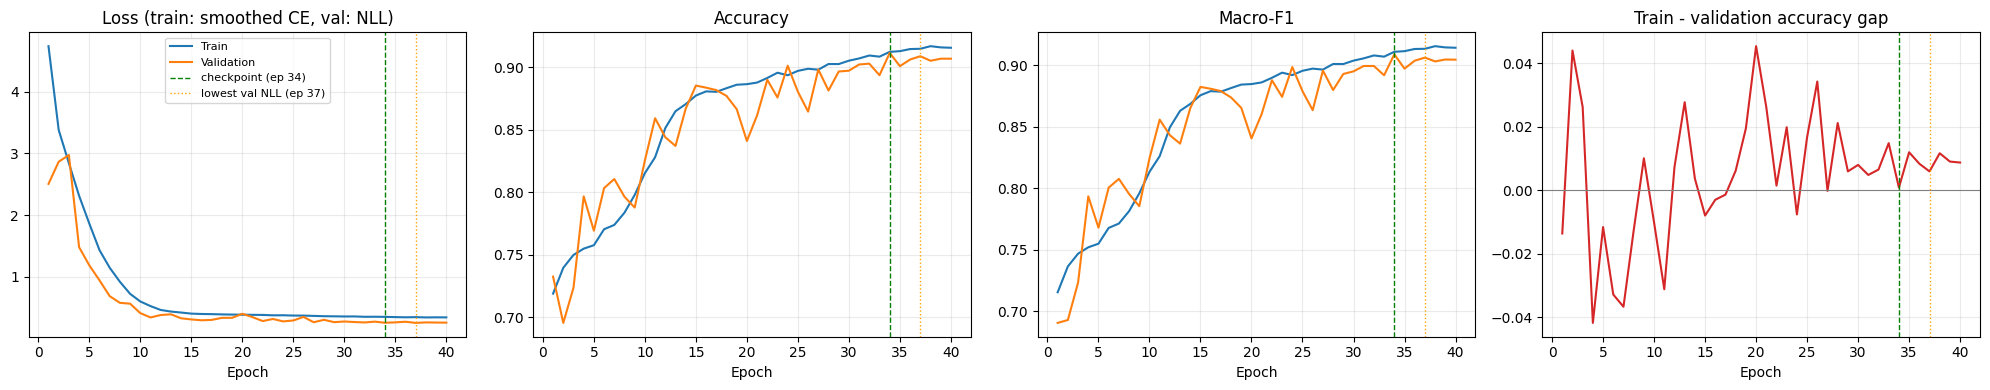

In [6]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
panels = [('loss', 'Loss (train: smoothed CE, val: NLL)'), ('accuracy', 'Accuracy'), ('macro_f1', 'Macro-F1')]
for ax, (metric, title) in zip(axes, panels):
    ax.plot(hist.epoch, hist[f'train_{metric}'], label='Train')
    ax.plot(hist.epoch, hist[f'val_{metric}'], label='Validation')
    ax.set_title(title)
axes[3].plot(hist.epoch, hist['train_val_acc_gap'], color='tab:red')
axes[3].axhline(0, color='grey', lw=0.8)
axes[3].set_title('Train - validation accuracy gap')
for ax in axes:
    ax.axvline(best_epoch, color='green', ls='--', lw=1, label=f'checkpoint (ep {best_epoch})')
    ax.axvline(lowest_val_nll_epoch, color='orange', ls=':', lw=1, label=f'lowest val NLL (ep {lowest_val_nll_epoch})')
    ax.set_xlabel('Epoch'); ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUT / 'training_curves.png', dpi=150)
plt.show()

## 6. Final evaluation

Evaluate the restored best-validation checkpoint once on the official test set, then report a separate subset excluding rows flagged by the audit. The paper-defined FDR is `FP/(TP+FP)`; FPR is also reported separately.

In [7]:
# Threshold selection uses validation only. The test set is not touched here.
@torch.no_grad()
def predict_probs(row_ids):
    loader = make_loader(row_ids)
    model.eval()
    ys, probs = [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == 'cuda'):
            logits = model(images)
        ys.extend(labels.numpy())
        probs.extend(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
    return np.asarray(ys), np.asarray(probs)

y_val, p_val = predict_probs(val_ids)
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
val_macro_f1 = np.array([f1_score(y_val, (p_val >= t).astype(np.int64), average='macro', zero_division=0)
                         for t in thresholds])
best_threshold = float(thresholds[int(np.argmax(val_macro_f1))])
at_half = float(val_macro_f1[int(np.argmin(np.abs(thresholds - 0.5)))])
print(f'Validation macro-F1 at threshold 0.50: {at_half:.4f}')
print(f'Validation macro-F1 at best threshold {best_threshold:.2f}: {val_macro_f1.max():.4f}')

Validation macro-F1 at threshold 0.50: 0.9090
Validation macro-F1 at best threshold 0.53: 0.9105


In [8]:
if not QUICK_TEST:
    # Read official test images only after training, checkpoint selection, and threshold selection.
    started = time.time()
    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 4)) as pool:
        for n, (row, pixels) in enumerate(pool.map(resize_row, test_ids), 1):
            cache[row] = pixels
            if n % 1000 == 0 or n == len(test_ids):
                print(f'Cached test {n:,}/{len(test_ids):,}')
    cache.flush()
    print(f'Test cache built in {(time.time() - started) / 60:.1f} min')

    def predict_rows(row_ids):
        ys, probs = predict_probs(row_ids)
        return ys, probs, (probs >= 0.5).astype(np.int64)

    def report_metrics(name, y, prob, pred):
        cm = confusion_matrix(y, pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        result = {
            'count': int(len(y)), 'threshold_note': name,
            'accuracy': float(accuracy_score(y, pred)),
            'precision_recyclable': float(precision_score(y, pred, pos_label=1, zero_division=0)),
            'recall_recyclable': float(recall_score(y, pred, pos_label=1, zero_division=0)),
            'f1_recyclable': float(f1_score(y, pred, pos_label=1, zero_division=0)),
            'macro_f1': float(f1_score(y, pred, average='macro', zero_division=0)),
            'auc': float(roc_auc_score(y, prob)),
            'mdr_fn_over_positives': float(fn / max(fn + tp, 1)),
            'fdr_fp_over_predicted_positives': float(fp / max(fp + tp, 1)),
            'fpr': float(fp / max(fp + tn, 1)),
            'confusion_matrix_tn_fp_fn_tp': [int(tn), int(fp), int(fn), int(tp)],
        }
        print(f'\n{name}:', json.dumps(result, indent=2))
        print(classification_report(y, pred, target_names=['Organic', 'Recyclable'], digits=4, zero_division=0))
        return result

    y_test, p_test, pred_test_05 = predict_rows(test_ids)
    pred_test = pred_test_05  # default reported predictions: threshold 0.5
    pred_test_tuned = (p_test >= best_threshold).astype(np.int64)
    clean_mask = df.loc[test_ids, 'test_leak'].to_numpy() == 0

    full_test = report_metrics('Official test, threshold 0.50', y_test, p_test, pred_test_05)
    clean_test = report_metrics('Test excluding audit-flagged images, threshold 0.50',
                                y_test[clean_mask], p_test[clean_mask], pred_test_05[clean_mask])
    threshold_tuned = abs(best_threshold - 0.5) > 1e-9
    if threshold_tuned:
        tuned_test = report_metrics(f'Official test, validation-tuned threshold {best_threshold:.2f}',
                                    y_test, p_test, pred_test_tuned)
        clean_tuned = report_metrics(f'Test excluding audit-flagged images, threshold {best_threshold:.2f}',
                                     y_test[clean_mask], p_test[clean_mask], pred_test_tuned[clean_mask])
    else:
        print('\nValidation-selected threshold is 0.50, so the tuned-threshold results equal the 0.50 results.')
        tuned_test, clean_tuned = full_test, clean_test

    pd.DataFrame({'path': df.loc[test_ids, 'resolved_path'].to_numpy(), 'label': y_test,
                  'prob_recyclable': p_test, 'pred_at_0.50': pred_test_05,
                  f'pred_at_{best_threshold:.2f}': pred_test_tuned,
                  'test_leak': df.loc[test_ids, 'test_leak'].to_numpy()}).to_csv(
                      OUT / 'predictions_test.csv', index=False)

    metrics = {'run': CONFIG['run'], 'reg_preset': REG_PRESET,
               'epochs_run': epochs_run, 'stopped_epoch': stopped_epoch,
               'lowest_val_nll_epoch': lowest_val_nll_epoch, 'lowest_val_nll': float(lowest_val_nll),
               'best_epoch': best_epoch, 'best_val_macro_f1': float(best_val_f1),
               'best_val_accuracy': float(best_val_acc),
               'train_val_acc_gap_at_best': float(best_row['train_val_acc_gap']),
               'training_gpu_hours': sum(r['epoch_time_s'] for r in history) / 3600,
               'validation_threshold': best_threshold,
               'validation_macro_f1_at_0.50': at_half,
               'splits_md5': splits_md5,
               'full_test_threshold_0.50': full_test, 'full_test_tuned_threshold': tuned_test,
               'clean_test_threshold_0.50': clean_test, 'clean_test_tuned_threshold': clean_tuned}
    (OUT / 'test_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    torch.save({'model_state': best_state, 'model_kw': MODEL_KW, 'run_config': CONFIG,
                'config': {'image_size': IMAGE_SIZE, 'mean': mean.tolist(), 'std': std.tolist(),
                           'label_map': {'organic': 0, 'recyclable': 1},
                           'threshold': best_threshold},
                'best_epoch': best_epoch, 'splits_md5': splits_md5}, OUT / 'best_weights.pt')
    print('Saved model and results to', OUT)

Cached test 1,000/2,513
Cached test 2,000/2,513
Cached test 2,513/2,513
Test cache built in 0.7 min

Official test, threshold 0.50: {
  "count": 2513,
  "threshold_note": "Official test, threshold 0.50",
  "accuracy": 0.9136490250696379,
  "precision_recyclable": 0.9552390640895219,
  "recall_recyclable": 0.8444244604316546,
  "f1_recyclable": 0.8964200477326969,
  "macro_f1": 0.9111919413006713,
  "auc": 0.9695502698483611,
  "mdr_fn_over_positives": 0.15557553956834533,
  "fdr_fp_over_predicted_positives": 0.044760935910478125,
  "fpr": 0.03140613847251963,
  "confusion_matrix_tn_fp_fn_tp": [
    1357,
    44,
    173,
    939
  ]
}
              precision    recall  f1-score   support

     Organic     0.8869    0.9686    0.9260      1401
  Recyclable     0.9552    0.8444    0.8964      1112

    accuracy                         0.9136      2513
   macro avg     0.9211    0.9065    0.9112      2513
weighted avg     0.9172    0.9136    0.9129      2513


Test excluding audit-flagged 

In [9]:
if not QUICK_TEST:
    # Compare audit-flagged and clean test images using the same predictions
    flag_mask = ~clean_mask
    def accuracy_of(mask):
        return float((pred_test[mask] == y_test[mask]).mean()), int(mask.sum())
    acc_flag, n_flag = accuracy_of(flag_mask)
    acc_clean, n_clean = accuracy_of(clean_mask)
    print(f'Flagged test images: n={n_flag}, accuracy={acc_flag:.4f}')
    print(f'Clean test images:   n={n_clean}, accuracy={acc_clean:.4f}')
    print(f'Gap (flagged - clean): {acc_flag - acc_clean:+.4f}')
    print('A large gap means the flagged images are easier than the rest, which is '
          'consistent with near-duplicate leakage. Report both numbers.')

Flagged test images: n=552, accuracy=0.9728
Clean test images:   n=1961, accuracy=0.8970
Gap (flagged - clean): +0.0758
A large gap means the flagged images are easier than the rest, which is consistent with near-duplicate leakage. Report both numbers.


## Reading the results

Fill this in after the run, using the numbers printed above.

- **Overfitting:** compare the final train and validation accuracy and loss in `history.csv`. A large gap that does not close means overfitting remains.
- **Threshold:** compare macro-F1 at 0.50 and at the validation-tuned threshold on the test set. The tuned threshold is only a validation choice, so do not select it again on test.
- **Leakage:** the gap between the full test set and the subset without flagged images shows how much the flagged images help. Report both numbers.
- **Comparison:** the table below puts the paper, the previous run, and this run side by side. A difference from the paper is not necessarily an error. Protocols differ (split, selection, learning rate).

## 7. Confusion matrix

The confusion matrix shown here is for the full official test set. The clean-subset metrics are reported above and in `test_metrics.json`.

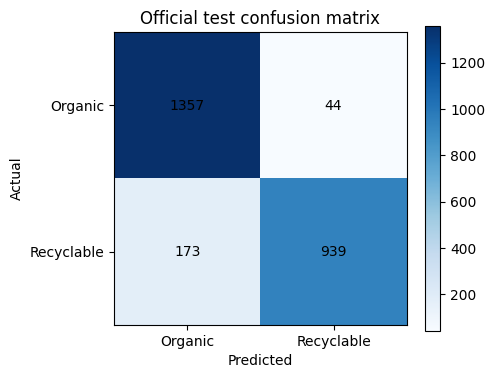

Output files: ['__notebook__.ipynb', 'best.pt', 'best_weights.pt', 'config.json', 'confusion_matrix_test.png', 'env.json', 'history.csv', 'last.pt', 'predictions_test.csv', 'test_metrics.json', 'training_curves.png']


In [10]:
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap='Blues')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Organic', 'Recyclable'],
       yticklabels=['Organic', 'Recyclable'], xlabel='Predicted', ylabel='Actual',
       title='Official test confusion matrix')
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha='center', va='center')
fig.colorbar(image, ax=ax); plt.tight_layout()
fig.savefig(OUT / 'confusion_matrix_test.png', dpi=150)
plt.show()
print('Output files:', sorted(p.name for p in OUT.iterdir()))

In [11]:
if not QUICK_TEST:
    # Comparison with the paper and with earlier runs of this pipeline.
    # Paper numbers are copied from Chhabra et al. (2024), Table 5 and Table 6.
    # Run 1 and run 2 numbers are copied from those runs' printed test output
    # (better: load their test_metrics.json once they are attached as Kaggle inputs).
    PAPER = {'accuracy': 0.9328, 'mdr': 0.026, 'fdr': 0.045}
    PREVIOUS = {'full_accuracy': 0.8647, 'full_recall_recyclable': 0.7635, 'full_precision_recyclable': 0.9168,
                'full_macro_f1': 0.8597, 'full_auc': 0.9309,
                'clean_accuracy': 0.8424, 'clean_recall_recyclable': 0.7350, 'clean_macro_f1': 0.8384,
                'clean_auc': 0.9167, 'best_val_accuracy': 0.8558}
    RUN2 = {'full_accuracy': 0.8945, 'full_recall_recyclable': 0.8049, 'full_macro_f1': 0.8909,
            'clean_accuracy': 0.8766, 'clean_recall_recyclable': 0.7842, 'clean_macro_f1': 0.8739,
            'best_val_accuracy': 0.9077, 'best_epoch': 100, 'epochs_run': 100,
            'lowest_val_nll': 0.2998, 'lowest_val_nll_epoch': 23, 'gpu_hours': 5.0}

    def implied_accuracy_range(n_pos, n_neg, mdr, fdr, tol=0.0015):
        """Accuracies consistent with MDR (= FN / positives) and FDR (= FP / predicted positives)."""
        accs = []
        for fn in range(n_pos + 1):
            tp = n_pos - fn
            if tp + fn == 0 or abs(fn / (tp + fn) - mdr) > tol:
                continue
            for fp in range(n_neg + 1):
                tn = n_neg - fp
                if tp + fp == 0 or abs(fp / (tp + fp) - fdr) > tol:
                    continue
                accs.append((tp + tn) / (n_pos + n_neg))
        return (min(accs), max(accs)) if accs else None

    n_pos = int((df.loc[test_ids, 'label'] == 1).sum())
    n_neg = int((df.loc[test_ids, 'label'] == 0).sum())
    lo_hi = implied_accuracy_range(n_pos, n_neg, PAPER['mdr'], PAPER['fdr'])
    print(f'Consistency check on the paper numbers (test class counts from this split: '
          f'Organic={n_neg}, Recyclable={n_pos}):')
    if lo_hi is None:
        print('  No accuracy is consistent with the paper MDR and FDR under these counts.')
    else:
        print(f'  MDR 2.6% and FDR 4.5% imply accuracy between {lo_hi[0]:.4f} and {lo_hi[1]:.4f}; '
              f'the paper reports {PAPER["accuracy"]:.4f}.')

    rows = [
        {'source': 'Paper (reported)', 'test': 'paper test set', 'accuracy': PAPER['accuracy'],
         'recall_recyclable': 1 - PAPER['mdr'], 'macro_f1': None,
         'selection': 'no validation set described; likely selected on test'},
        {'source': 'Run 1', 'test': 'full test', 'accuracy': PREVIOUS['full_accuracy'],
         'recall_recyclable': PREVIOUS['full_recall_recyclable'], 'macro_f1': PREVIOUS['full_macro_f1'],
         'selection': 'validation checkpoint, threshold 0.50'},
        {'source': 'Run 1', 'test': 'without flagged', 'accuracy': PREVIOUS['clean_accuracy'],
         'recall_recyclable': PREVIOUS['clean_recall_recyclable'], 'macro_f1': PREVIOUS['clean_macro_f1'],
         'selection': 'validation checkpoint, threshold 0.50'},
        {'source': 'Run 2 (100 ep)', 'test': 'full test', 'accuracy': RUN2['full_accuracy'],
         'recall_recyclable': RUN2['full_recall_recyclable'], 'macro_f1': RUN2['full_macro_f1'],
         'selection': 'best val accuracy (epoch 100), threshold 0.50'},
        {'source': 'Run 2 (100 ep)', 'test': 'without flagged', 'accuracy': RUN2['clean_accuracy'],
         'recall_recyclable': RUN2['clean_recall_recyclable'], 'macro_f1': RUN2['clean_macro_f1'],
         'selection': 'best val accuracy (epoch 100), threshold 0.50'},
        {'source': f'Run 3 ({epochs_run} ep)', 'test': 'full test', 'accuracy': full_test['accuracy'],
         'recall_recyclable': full_test['recall_recyclable'], 'macro_f1': full_test['macro_f1'],
         'selection': f'best val macro-F1 (epoch {best_epoch}), threshold 0.50'},
        {'source': f'Run 3 ({epochs_run} ep)', 'test': 'without flagged', 'accuracy': clean_test['accuracy'],
         'recall_recyclable': clean_test['recall_recyclable'], 'macro_f1': clean_test['macro_f1'],
         'selection': f'best val macro-F1 (epoch {best_epoch}), threshold 0.50'},
    ]
    if threshold_tuned:
        rows.append({'source': f'Run 3 ({epochs_run} ep)', 'test': 'full test', 'accuracy': tuned_test['accuracy'],
                     'recall_recyclable': tuned_test['recall_recyclable'], 'macro_f1': tuned_test['macro_f1'],
                     'selection': f'best val macro-F1, threshold {best_threshold:.2f} (chosen on val)'})
    comparison = pd.DataFrame(rows)
    print('\n' + comparison.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

    print('\nOverfitting / budget, run 2 vs run 3:')
    print(pd.DataFrame([
        {'run': 'Run 2', 'epochs_run': RUN2['epochs_run'], 'selected_epoch': RUN2['best_epoch'],
         'lowest_val_nll': RUN2['lowest_val_nll'], 'lowest_val_nll_epoch': RUN2['lowest_val_nll_epoch'],
         'gpu_hours': RUN2['gpu_hours']},
        {'run': 'Run 3', 'epochs_run': epochs_run, 'selected_epoch': best_epoch,
         'lowest_val_nll': lowest_val_nll, 'lowest_val_nll_epoch': lowest_val_nll_epoch,
         'gpu_hours': metrics['training_gpu_hours']},
    ]).to_string(index=False, float_format=lambda v: f'{v:.4f}'))
    (OUT / 'comparison.json').write_text(json.dumps(
        {'paper': PAPER, 'run1': PREVIOUS, 'run2': RUN2, 'this_run': metrics,
         'paper_implied_accuracy_range': lo_hi, 'table': rows}, indent=2, default=float), encoding='utf-8')

Consistency check on the paper numbers (test class counts from this split: Organic=1401, Recyclable=1112):
  MDR 2.6% and FDR 4.5% imply accuracy between 0.9674 and 0.9690; the paper reports 0.9328.

          source            test  accuracy  recall_recyclable  macro_f1                                            selection
Paper (reported)  paper test set    0.9328             0.9740       NaN no validation set described; likely selected on test
           Run 1       full test    0.8647             0.7635    0.8597                validation checkpoint, threshold 0.50
           Run 1 without flagged    0.8424             0.7350    0.8384                validation checkpoint, threshold 0.50
  Run 2 (100 ep)       full test    0.8945             0.8049    0.8909        best val accuracy (epoch 100), threshold 0.50
  Run 2 (100 ep) without flagged    0.8766             0.7842    0.8739        best val accuracy (epoch 100), threshold 0.50
   Run 3 (40 ep)       full test    0.9136        